In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/cleaned_data.csv")

In [2]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

In [3]:
import datetime as dt

reference_date = df['order_purchase_timestamp'].max()

In [4]:
rfm = df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (reference_date - x.max()).days,
    'order_id': 'nunique',
    'revenue': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

In [5]:
rfm.head()

,Recency,Frequency,Monetary
customer_id,,,
00012a2ce6f8dcda20d059ce98491703,337,1,89.80
000161a058600d5901f007fab4c27140,458,1,54.90
0001fd6190edaaf884bcaf3d49edf079,596,1,179.99
0002414f95344307404f0ace7a26f1d5,427,1,149.90
000379cdec625522490c315e70c7a9fb,198,1,93.00


In [6]:
rfm['R_score'] = pd.qcut(rfm['Recency'], 4, labels=[4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1,2,3,4])
rfm['M_score'] = pd.qcut(rfm['Monetary'], 4, labels=[1,2,3,4])

In [7]:
rfm['RFM_Score'] = rfm[['R_score','F_score','M_score']].astype(str).agg(''.join, axis=1)

In [8]:
def segment(row):
    if row['RFM_Score'] in ['444','443','434','344']:
        return 'Loyal Customers'
    elif row['RFM_Score'] in ['111','112','121']:
        return 'At Risk'
    else:
        return 'Average'

rfm['Segment'] = rfm.apply(segment, axis=1)

In [9]:
rfm['Segment'].value_counts()

Segment
Average            88498
Loyal Customers     6240
At Risk             4703
Name: count, dtype: int64

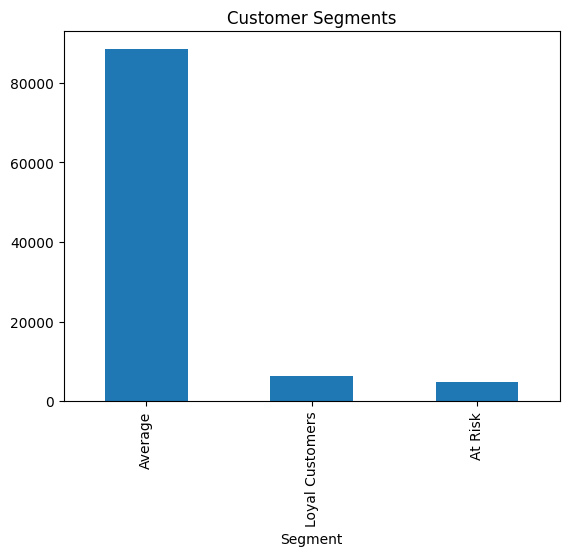

In [10]:
import matplotlib.pyplot as plt

rfm['Segment'].value_counts().plot(kind='bar')
plt.title("Customer Segments")
plt.show()